In [20]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
device = "ibm_marrakesh"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

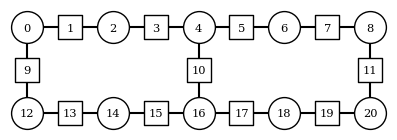

In [21]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 2
plaquette_height = 1

HeavyHexLattice(plaquette_width, plaquette_height).plot_lattice(number_qubits=True)

In [22]:
from utils.hexec import ExecDB
import numpy as np

lattice_dimensions = (2, 1)

J_1d = 5
J_rest = 25
h_1d = 0.8
h_rest = 25
lamb_1d = 1
lamb_rest = 0
g = 10

chain_qubits_on_lattice = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 11, 20, 19, 18, 17, 16, 15, 14, 13, 12])
particle_pair_left_position = 2
particle_pair_length = 5
string_arr = [chain_qubits_on_lattice[2*particle_pair_left_position]]
string_arr += chain_qubits_on_lattice[2*particle_pair_left_position + 1:2*particle_pair_left_position + 2*particle_pair_length + 1:2].tolist()
string_arr += [chain_qubits_on_lattice[2*particle_pair_left_position+2*particle_pair_length]]
string_arr = [int(qb) for qb in string_arr]

x_basis = False

final_time = 5
dt = 0.15
steps = 40
confidence = 0.7

shots = 300000

odr = True
flip_threshold = None
all_or_first_layout_qubit = True
forbidden_qubits = []
max_layouts = 4
fractional_gates = False

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    }
}

execution_database = "z2_hex_jobs_sanity_checks.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

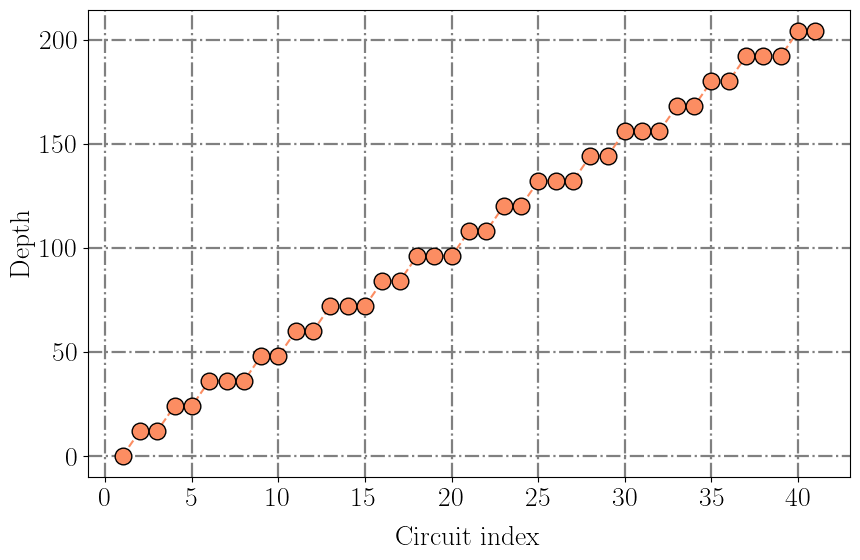

In [23]:
from z2hex.circs import string_quench_simulation_circuits_dt, odr_compuncomp_circuits_dt, get_layouts
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.plotting import plot_circuit_arr_depth
from utils.circs import generate_and_save_circs
from z2hex.geometry import HeavyHexLattice
from functools import partial
from itertools import product
import numpy as np
import os

lattice = HeavyHexLattice(*lattice_dimensions)

layout_node_qinds = lattice.coords_to_logical_qb(lattice.node_coords)
layout_gauge_quinds = lattice.coords_to_logical_qb(lattice.edge_coords)

Js = np.full(len(lattice.node_coords), J_rest, dtype=float)
for qbind in chain_qubits_on_lattice[::2]:
    lind = np.where(np.equal(layout_node_qinds, qbind))[0]
    Js[lind] = J_1d
hs = np.full(len(lattice.edge_coords), h_rest, dtype=float)
lambdas = np.full(len(lattice.edge_coords), lamb_rest, dtype=float)
for qbind in chain_qubits_on_lattice[1::2]:
    lind = np.where(np.equal(layout_gauge_quinds, qbind))[0]
    hs[lind] = h_1d
    lambdas[lind] = lamb_1d

layouts = np.array(get_layouts(lattice, backend, all_or_first_layout_qubit, forbidden_qubits))
if layouts.shape[0] > max_layouts:
    rand_idx = np.random.choice(layouts.shape[0], max_layouts, replace=False)
    layouts = layouts[rand_idx, :]

optimization_level = 3

circs_args = (lattice, Js, hs, lambdas, string_arr, final_time, dt, steps, backend, optimization_level, g, layouts, x_basis, True, False)
circuits = string_quench_simulation_circuits_dt(*circs_args)
extra_options = {"backend": device, "plaquette_width": lattice_dimensions[0], "plaquette_height": lattice_dimensions[1], "J": Js.tolist(), "h": hs.tolist(), "λ":lambdas.tolist(), "g": g, "string_arr": string_arr, "final_time": final_time, "dt": dt, "steps": steps, "first_qubit": all_or_first_layout_qubit} | ({"fractional_gates": True} if fractional_gates else {})
if odr:
    odr_func_args = (lattice, Js, hs, lambdas, final_time, dt, steps, backend, g, string_arr, layouts, x_basis)
    odr_circuits = odr_compuncomp_circuits_dt(*odr_func_args)
observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_x(lattice, i) if x_basis else local_pauli_z(lattice, i)) for i in range(len(lattice))]
postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis)

# circuits[0][0][1].draw(output="mpl", idle_wires=False)
plot_circuit_arr_depth(circuits[0])

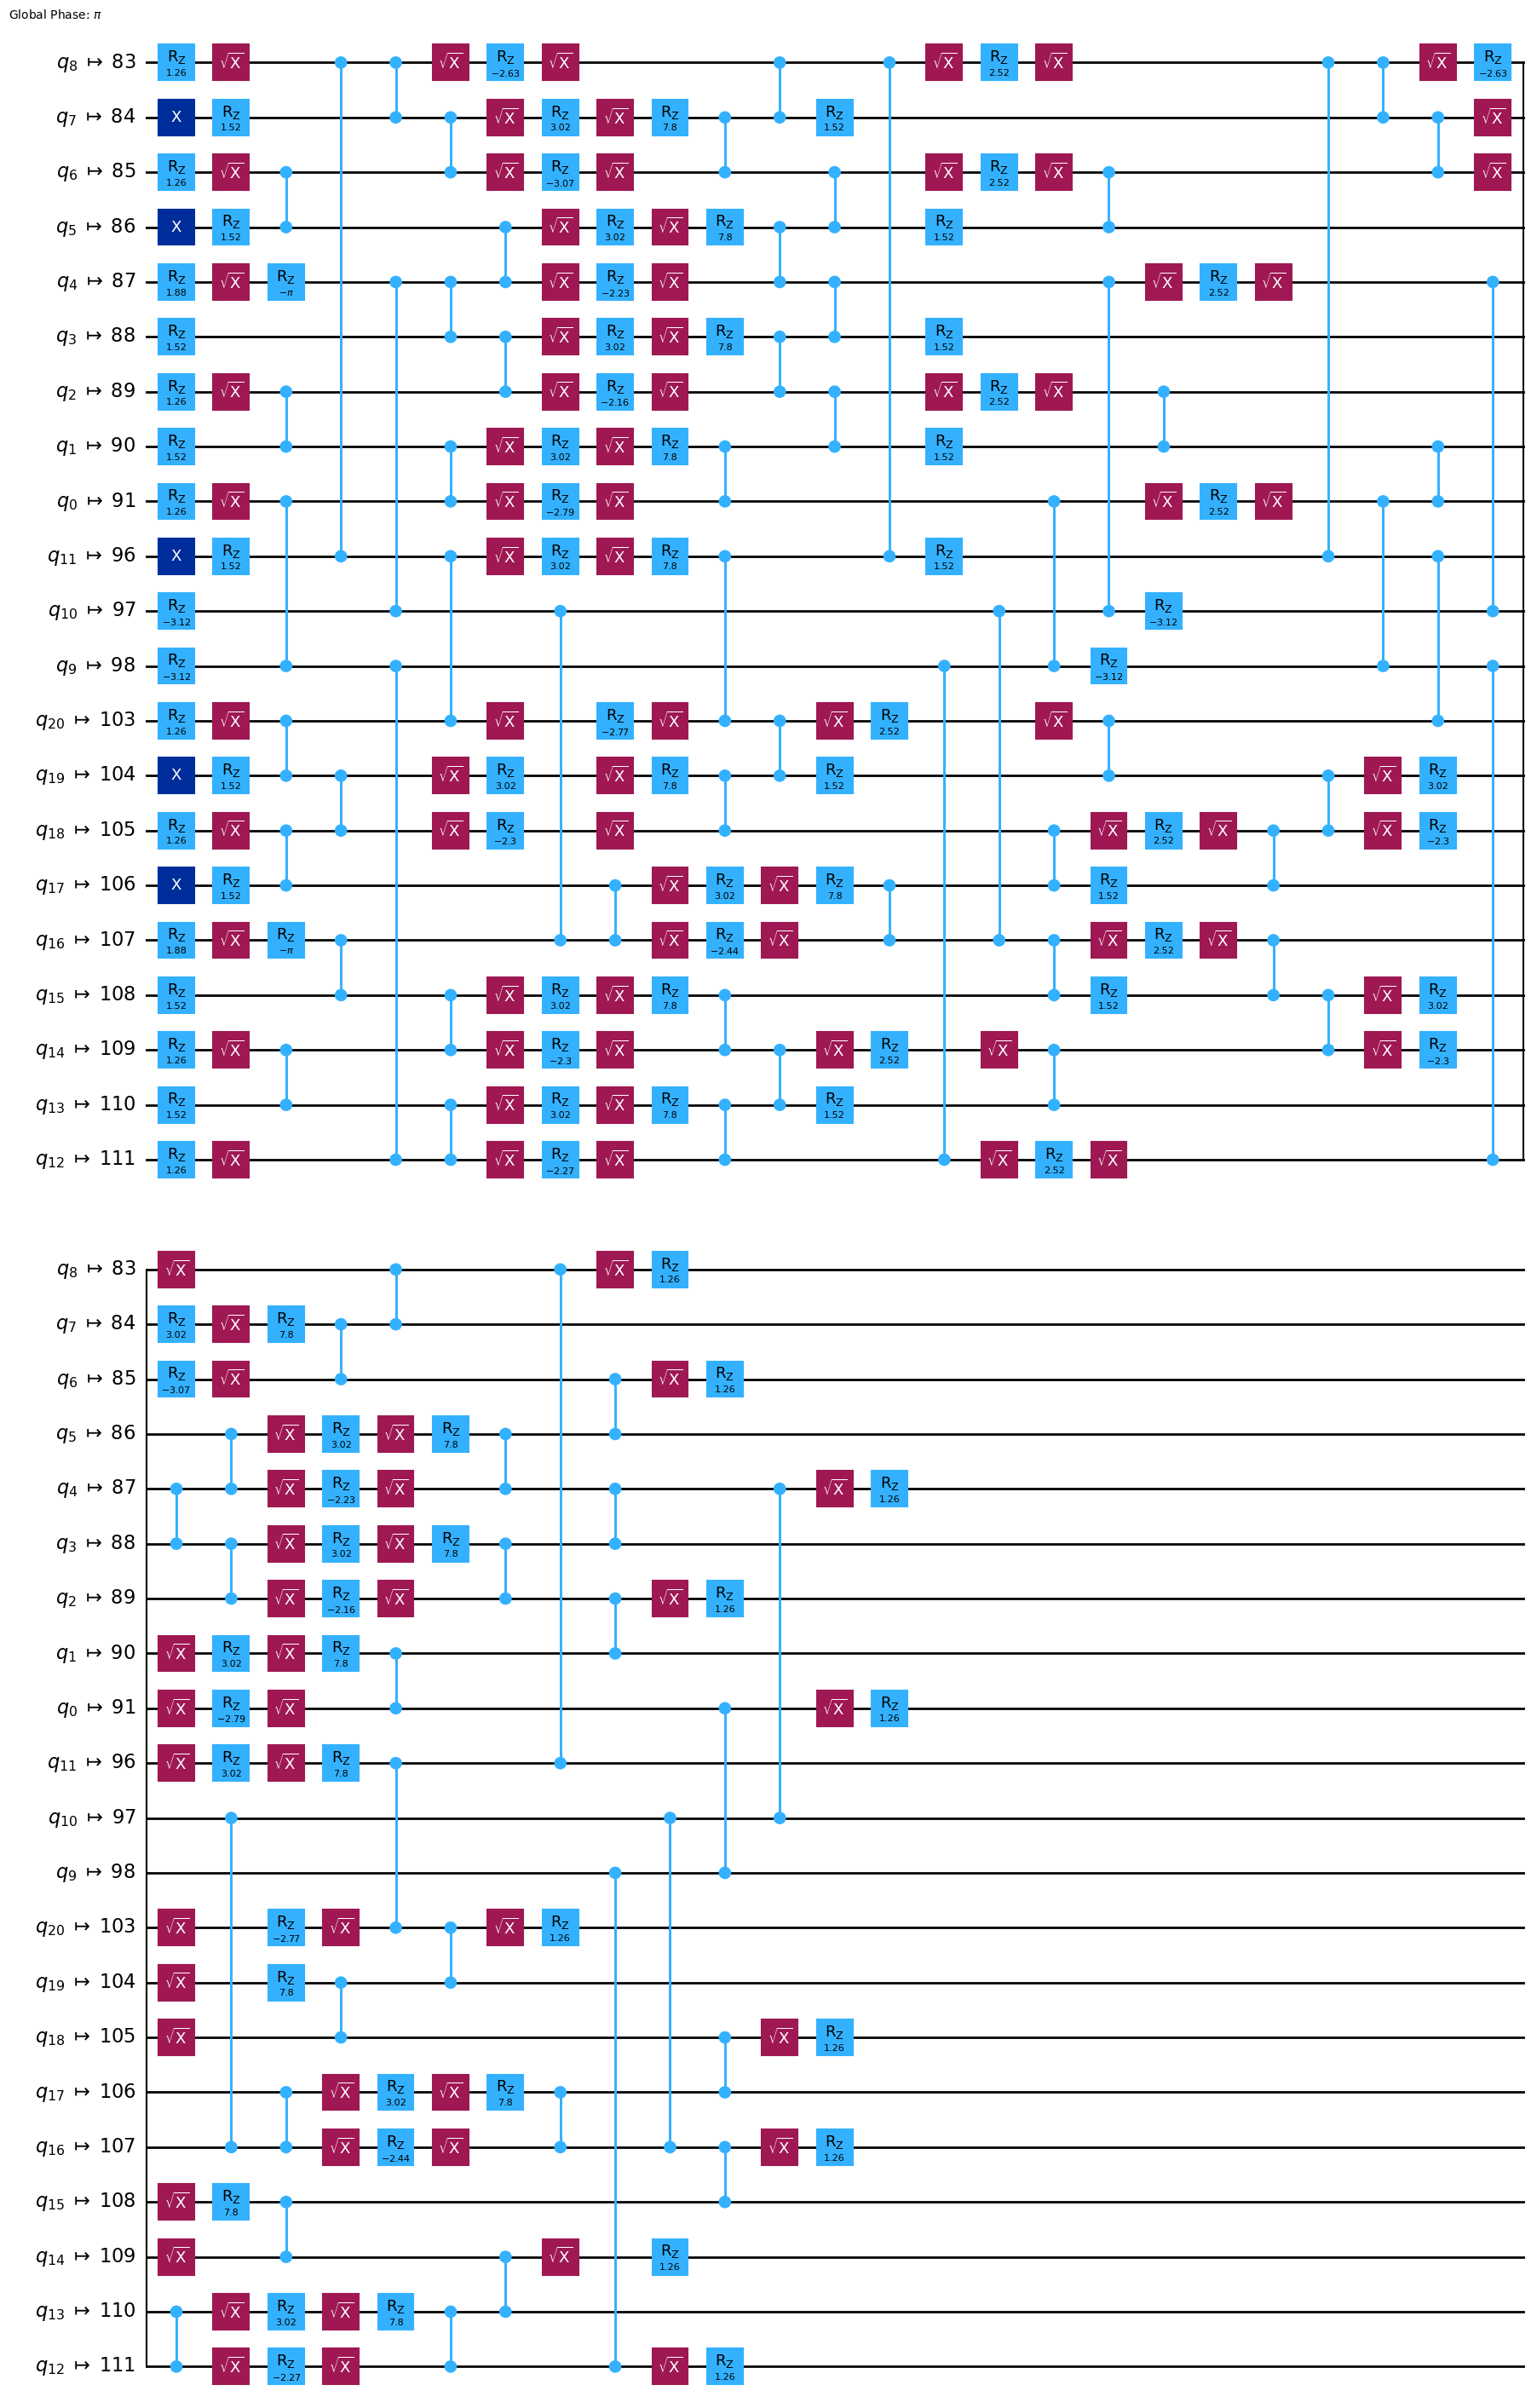

In [33]:
circuits[0][1].draw(output="mpl", idle_wires=False, filename="circs_sanity_simulation.pdf")

In [24]:
from utils.sexec import execute_simulation_estimator_batch

estimator_options = {
    "default_precision": 1e-8
}

simulator_options = {
    "method": "matrix_product_state",
    "matrix_product_state_max_bond_dimension": 512,
    "matrix_product_state_truncation_threshold": 1e-12
}

this_jobs = execute_simulation_estimator_batch(simulator_options, estimator_options, circuits[0], observable_generating_funcs)

In [25]:
from utils.plotting import convert_jobs_to_site_gauge_matrix

observables = convert_jobs_to_site_gauge_matrix(this_jobs)

In [26]:
observables[0, chain_qubits_on_lattice]

array([-5.72881576e-09, -3.17888693e-09,  7.93927712e-09, -1.13141185e-09,
        1.00000000e+00,  1.00000000e+00, -1.36179031e-08,  9.99999998e-01,
       -6.42378439e-09,  1.00000000e+00,  1.72499848e-10,  1.00000001e+00,
       -3.59395980e-09,  1.00000000e+00,  1.00000000e+00, -4.30615499e-09,
       -4.93818875e-10,  2.72380501e-09,  6.38589071e-10])

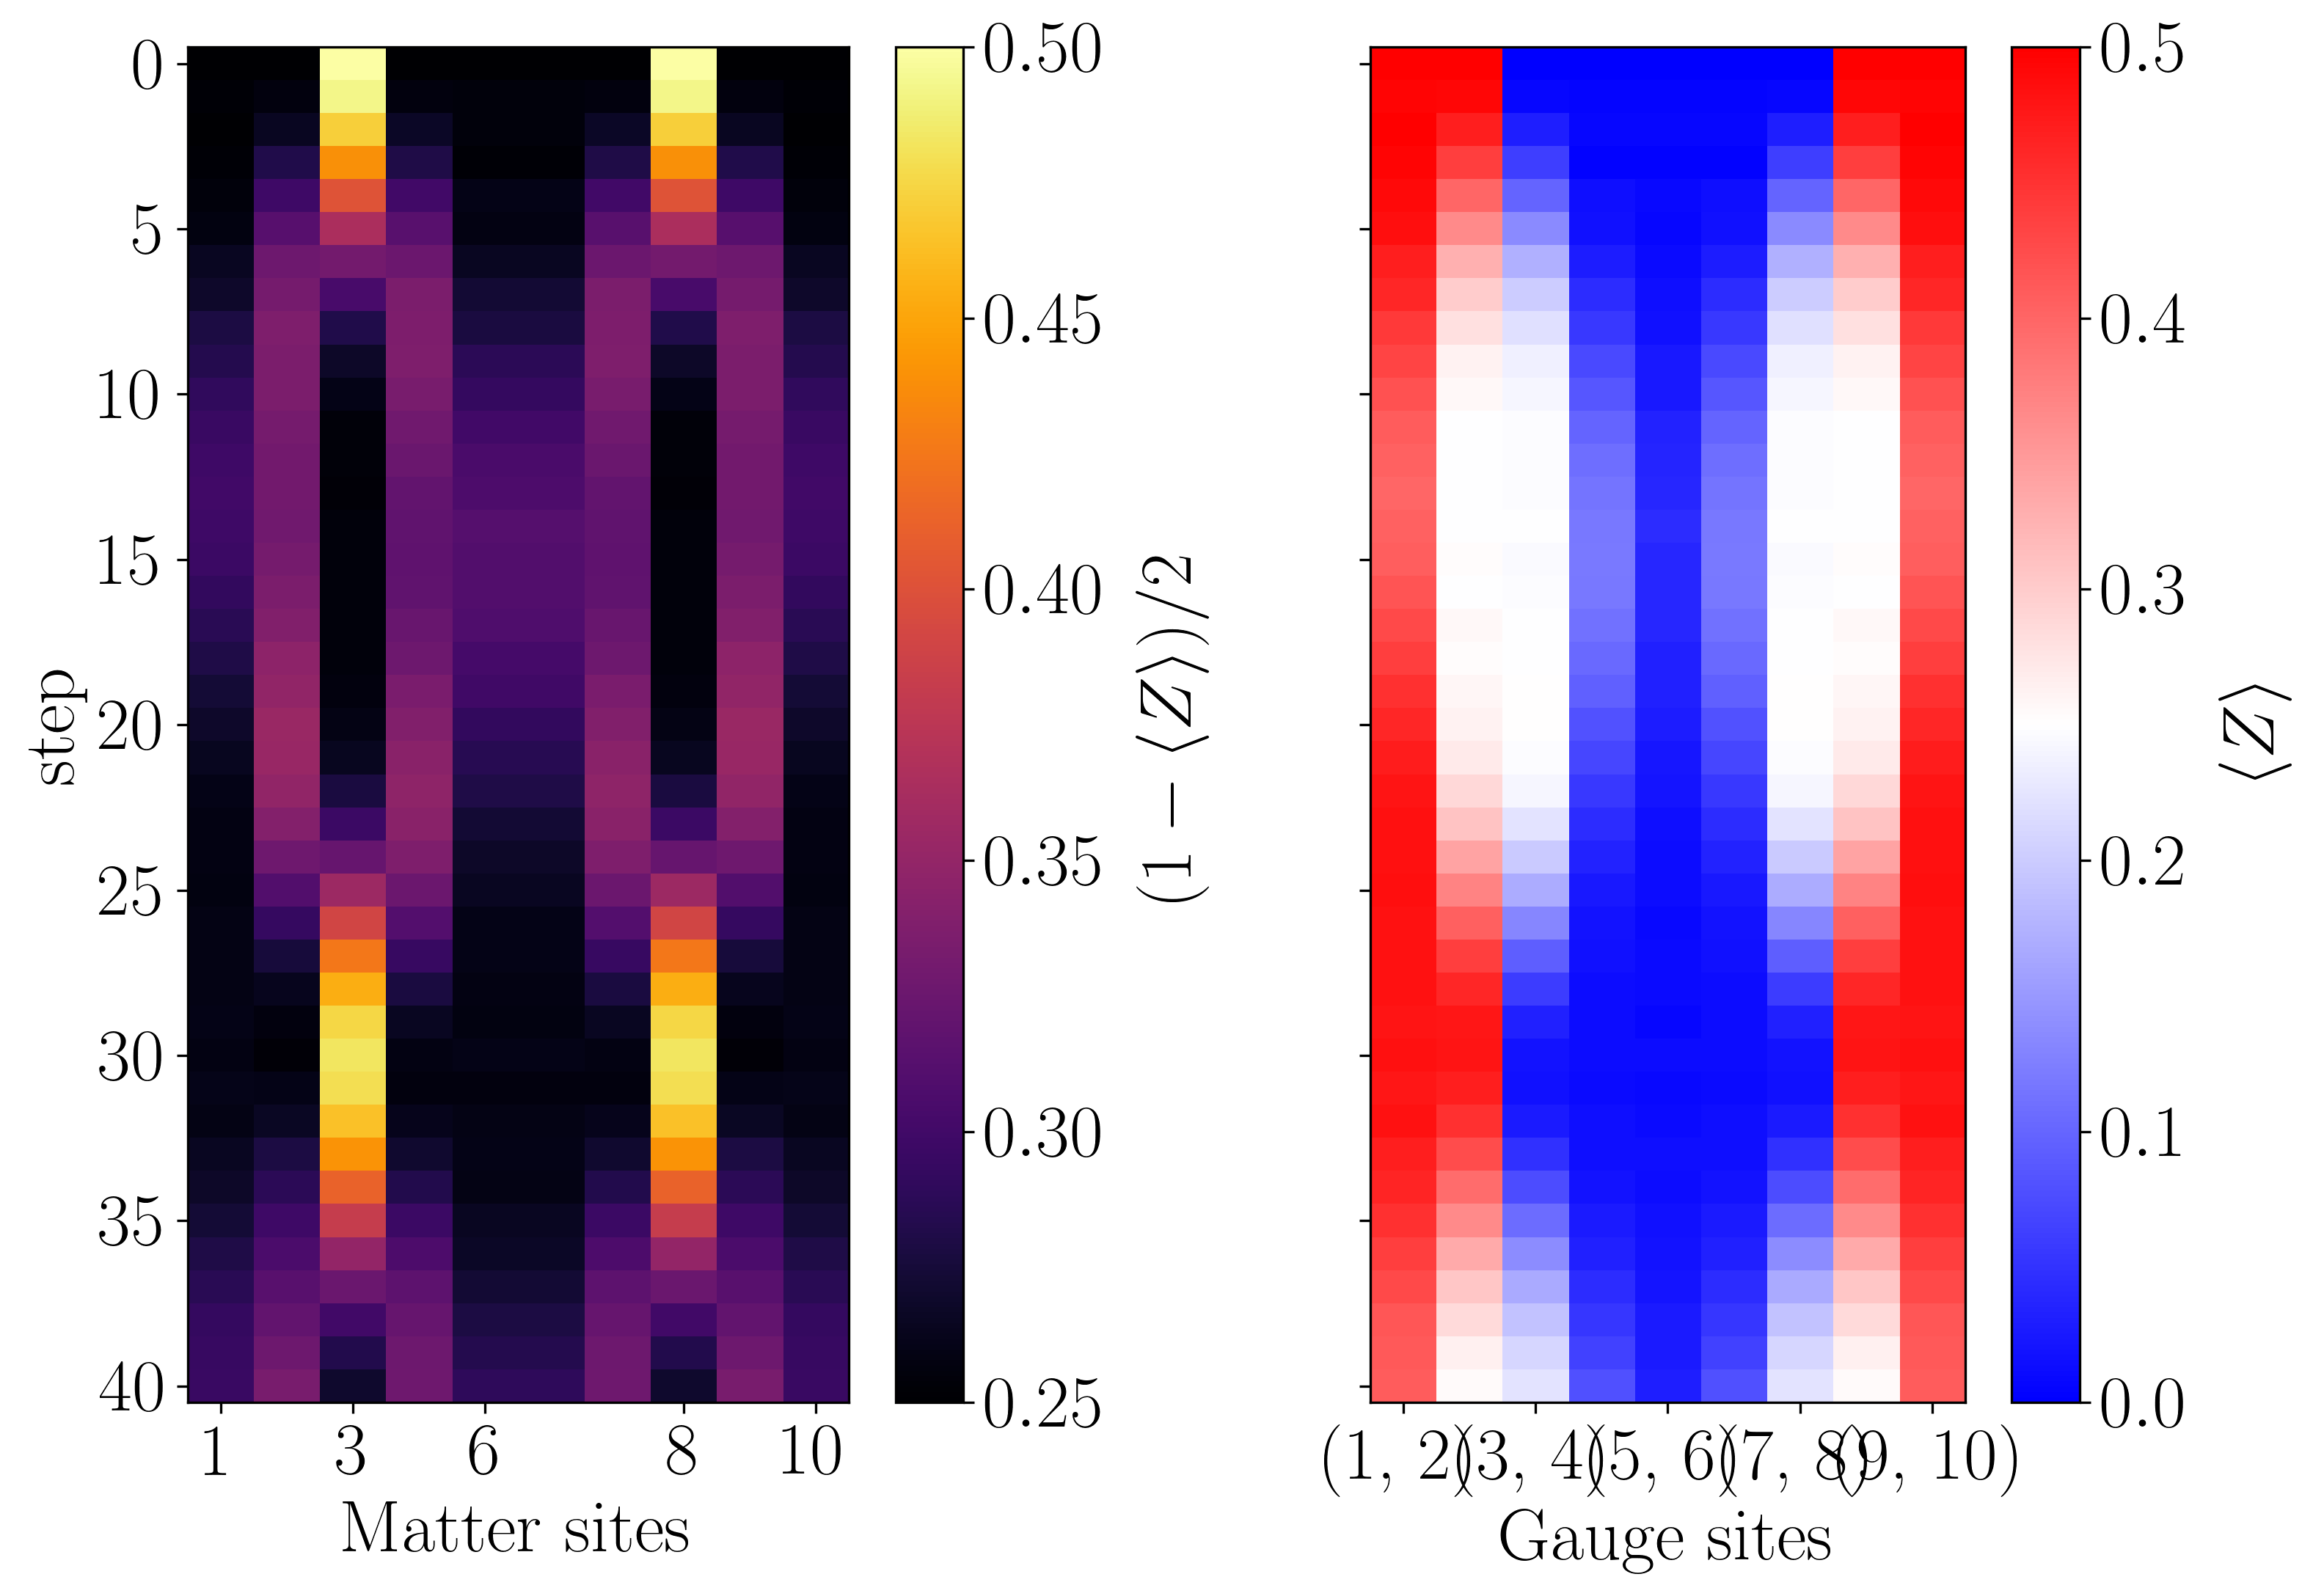

In [27]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot((1 - observables[:, chain_qubits_on_lattice])/2)

In [30]:
observables[0]

array([-5.72881576e-09, -3.17888693e-09,  7.93927712e-09, -1.13141185e-09,
        1.00000000e+00,  1.00000000e+00, -1.36179031e-08,  9.99999998e-01,
       -6.42378439e-09, -4.11801704e-11,  8.85176238e-09,  1.00000000e+00,
        6.38589071e-10,  2.72380501e-09, -4.93818875e-10, -4.30615499e-09,
        1.00000000e+00,  1.00000000e+00, -3.59395980e-09,  1.00000001e+00,
        1.72499848e-10])